### Import Dataset

Copy code from classroom-analysis.ipynb to get the correct preprocessing

#### Preprocessing Code that is reused

In [13]:
import pandas as pd
import numpy as np

df = pd.read_csv('data/courses-classrooms.csv', index_col=False)

df['start time'] = pd.to_datetime(df['start time'])
df['stop time'] = pd.to_datetime(df['stop time'])
earliest_start = df['start time'].min()
df['start time'] = df['start time'].apply(lambda d: (d - earliest_start).total_seconds() / 60)
df['stop time'] = df['stop time'].apply(lambda d: (d - earliest_start).total_seconds() / 60)

data = df.to_numpy()[:, 1:]
_STU = 0
_CAP = 1
_START = 2
_END = 3
_IN_B = 4
_ON_F = 5
_AC = 6


C:\Users\chris\AppData\Local\Temp\ipykernel_15764\301976379.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['start time'] = pd.to_datetime(df['start time'])
C:\Users\chris\AppData\Local\Temp\ipykernel_15764\301976379.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['stop time'] = pd.to_datetime(df['stop time'])


In [9]:
data_by_floor = {}
for row in data:
    building_floor = row[0]
    if building_floor not in data_by_floor:
        data_by_floor[building_floor] = np.expand_dims(row[1:], axis=0)
    else:
        x = data_by_floor[building_floor]
        data_by_floor[building_floor] = np.vstack([x, row[1:]])

floor_statuses = {}
for row in data:
    building_floor = row[0]
    if building_floor not in floor_statuses:
        floor_statuses[building_floor] = (row[5], row[6])

#### Allow for factoring out rooms in the time series function

In [10]:
def get_time_series(values, starts, ends, t):
    n_t = len(t)
    N = len(values)

    T = np.repeat(np.expand_dims(t, axis=1), N, axis=1).T
    S = np.repeat(np.expand_dims(starts, axis=1), n_t, axis=1)
    E = np.repeat(np.expand_dims(ends, axis=1), n_t, axis=1)
    V = np.repeat(np.expand_dims(values, axis=1), n_t, axis=1)

    during_class = (S <= T) * (T <= E)
    return np.sum(during_class * V, axis=0), np.sum(during_class * V)


In [11]:
df.head()

,Unnamed: 0,building floor,students,Capacity,start time,stop time,Filler In Building,Filler On Floor,A/C,Mon,Tue,Wed,Thu,Fri
0,0,SOC 2,34.0,35.0,300.0,375.0,True,False,True,False,True,False,True,False
1,1,SOC 2,35.0,35.0,445.0,495.0,True,False,True,False,False,True,False,False
2,2,SOC 2,34.0,35.0,390.0,555.0,True,False,True,False,True,False,False,False
3,3,SOC 2,35.0,35.0,300.0,375.0,True,False,True,False,True,False,True,False
4,4,SOC 2,13.0,35.0,210.0,285.0,True,False,True,False,True,False,True,False


In [18]:
max_t = df['stop time'].max()
dt = 15
t = np.arange(0, max_t, dt)

floors_with_no_filler = [(key, x) for key, x in data_by_floor.items() if floor_statuses[key][1] == False]
without_ac = [(key, x[x[:, _AC] == False]) for key, x in data_by_floor.items()]
all_results = [(key, get_time_series(x[:, _STU], x[:, _START], x[:, _END], t)) for key, x in without_ac]
results = [[key, x[1], x[0]] for key, x in all_results if not np.isnan(x[1])]

top_auc = sorted(results, key=lambda x: x[1], reverse=True)
k = 10

print("---- Building Floors with high density of students in no AC and with no filler ----- ")
for i in range(k):
    print(f"{i}. {top_auc[i][0]} with AUC {top_auc[i][1]}")

---- Building Floors with high density of students in no AC and with no filler ----- 
0. SOC 2 with AUC 0
1. CAS 2 with AUC 0
2. COM 1 with AUC 0
3. PSY b with AUC 0
4. SOC b with AUC 0
5. KCB 1 with AUC 0
6. CDS 2 with AUC 0
7. FLR 2 with AUC 0
8. CAS b with AUC 0
9. CAS 3 with AUC 0


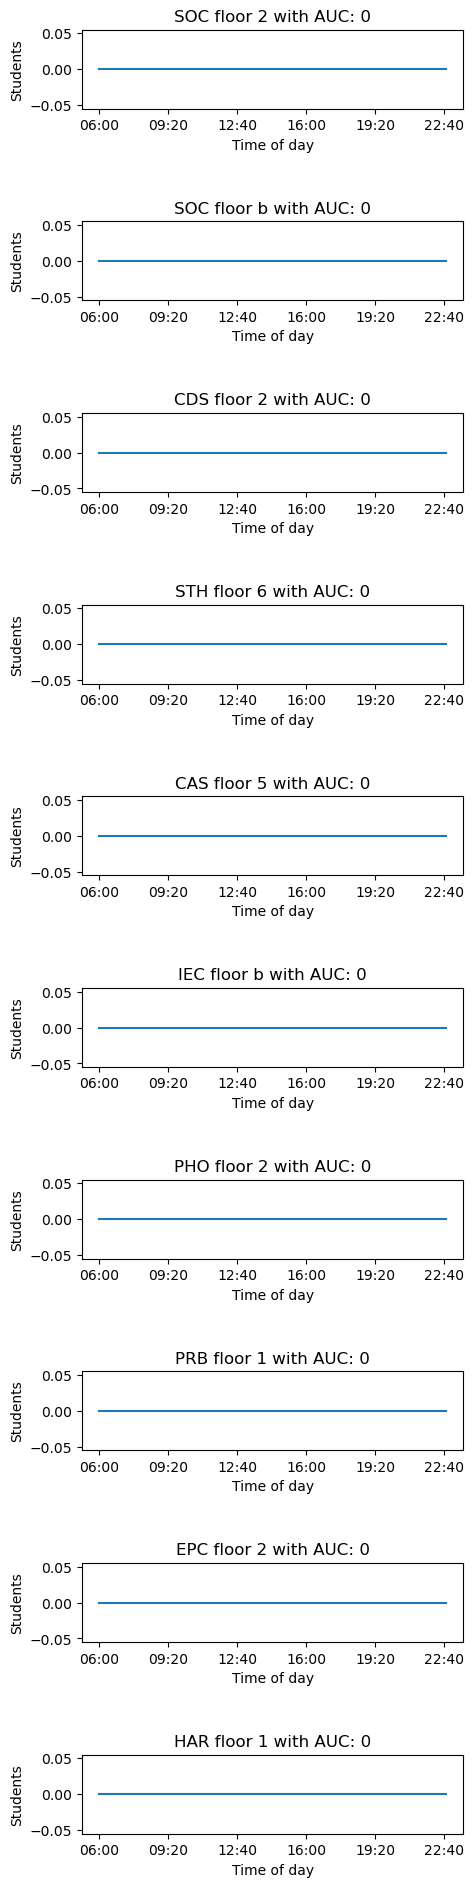

In [17]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(10, 1, figsize=(6, 20))
fig.tight_layout(pad=6)

t_ticks = list(np.arange(0, 1001, 200))
times = [(earliest_start + pd.DateOffset(minutes=int(t_tick))).time() for t_tick in t_ticks]
str_times = [time.strftime("%H:%M") for time in times]

for i in range(10):
    y = top_auc[i][2]
    ax[i].plot(t, y)
    ax[i].set_xlabel('Time of day')
    ax[i].set_ylabel('Students')
    ax[i].set_xticks(t_ticks, str_times)
    building, floor = top_auc[i][0].split(' ')
    ax[i].set_title(f"{building} floor {floor} with AUC: {top_auc[i][1]}")